## Exploring Double Integrals via Riemann Sums

In this activity, we will approximate a **double integral** over a rectangular region
using **Riemann sums**. We’ll visualize how increasing the number of rectangles
makes the approximation closer to the true value.

We'll also look at double integrals over non rectangular regions utilizing Monte Carlo integration.

FYI - This lab was created with the help of ChatGPT

We'll start with a simple surface:
$$
f(x, y) = x^2 + y^2
$$
and integrate over the rectangle:
$$
0 \le x \le 1, \quad 0 \le y \le 2
$$
**Problem 1**. Define the function and the bounds

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

In [2]:
def f(x, y):
    return x**2 + y**2

a, b = 0, 1  # x bounds
c, d = 0, 2  # y bounds


# Construct a Riemann Sum Approximation

The double integral is approximated as:
 $$
 \iint_R f(x, y) \, dA \approx \sum_{i=1}^{n_x} \sum_{j=1}^{n_y} f(x_i^*, y_j^*) \, \Delta x \, \Delta y
 $$

 where $ x_i^* $ and $ y_j^* $ are sample points in each subrectangle.

**Convince yourself** that seqential x's have the spacing given by dx calculated in the code only if `nx+1` is used in linespace (and not `nx`)

**Problem 2** Write code so that your function is sampled at the *midpoint* of the box.

In [3]:
def riemann_sum(f, a, b, c, d, nx, ny):
    x = np.linspace(a, b, nx + 1) # note the +1, this gives nx boxes, which have nx+1 edges
    y = np.linspace(c, d, ny + 1)
    dx = (b - a) / nx
    dy = (d - c) / ny

    # midpoints for each rectangle
    x_st = (x[:-1] + x[1:]) / 2
    y_st = (y[:-1] + y[1:]) / 2

    X, Y = np.meshgrid(x_st, y_st)
    Z = f(X, Y)

    return Z.sum() * dx * dy

nx = 5
ny = 10
riemann_sum(f, a, b, c, d, nx, ny)

np.float64(3.320000000000001)

**Problem 3** Start with something small, like `nx=4`,`ny=4` and increase these values to see how the approximation changes.  Print out the values of the integration and also provide a plot vs. n.



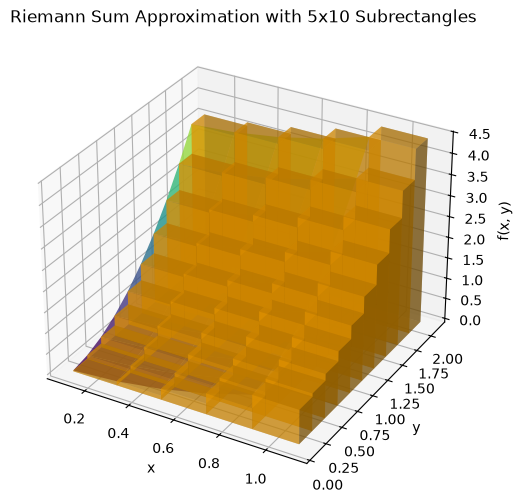

In [4]:
# Here is some code to visualize what is begin computed
def plot_riemann_sum(f, a, b, c, d, nx, ny):
    x = np.linspace(a, b, nx + 1)
    y = np.linspace(c, d, ny + 1)
    dx = (b - a) / nx
    dy = (d - c) / ny
    x_mid = (x[:-1] + x[1:]) / 2
    y_mid = (y[:-1] + y[1:]) / 2
    X, Y = np.meshgrid(x_mid, y_mid, indexing='ij')
    Z = f(X, Y)

    fig = plt.figure(figsize=(8,6))
    ax = fig.add_subplot(111, projection='3d')

    ax.plot_surface(X, Y, Z, cmap='viridis', alpha=0.8)
    ax.bar3d(X.ravel(), Y.ravel(), np.zeros_like(Z.ravel()), dx, dy, Z.ravel(),
             color='orange', alpha=0.5, shade=True)

    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_zlabel('f(x, y)')
    ax.set_title(f"Riemann Sum Approximation with {nx}x{ny} Subrectangles")
    plt.show()

nx = 5
ny = 10
plot_riemann_sum(f, a, b, c, d, nx, ny)

In [5]:
ns = np.array([4, 8, 16, 32, 64, 128])
approxs = np.array([riemann_sum(f, a, b, c, d, n, n) for n in ns])

for n, approx in zip(ns, approxs):
    print(f"n = {n:3d}, integral ≈ {approx:.9f}")

n =   4, integral ≈ 3.281250000
n =   8, integral ≈ 3.320312500
n =  16, integral ≈ 3.330078125
n =  32, integral ≈ 3.332519531
n =  64, integral ≈ 3.333129883
n = 128, integral ≈ 3.333282471


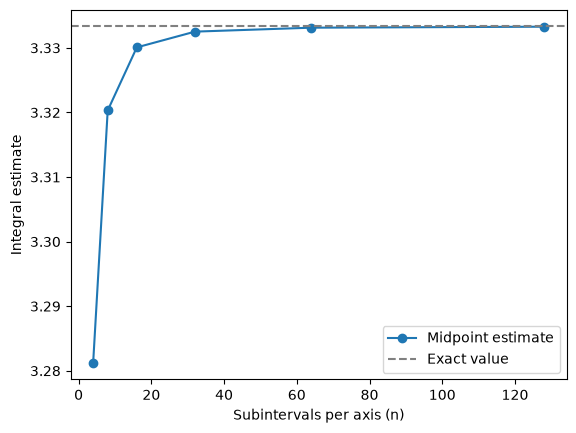

In [6]:
plt.plot(ns, approxs, "o-", label="Midpoint estimate")
plt.axhline(10/3, color="gray", linestyle="--", label="Exact value")
plt.xlabel("Subintervals per axis (n)")
plt.ylabel("Integral estimate")
plt.legend()
plt.show()

**Problem 4** Comment on what you observe.  Approximately what value of $n$ do you need to get three digits of accuracy?

The midpoint estimates increase toward $10/3=3.333333\ldots$ from below. For three significant digits, $n=11$ gives $3.326446$, which rounds to $3.33$. If three decimal places are intended, $n=32$ gives $3.332520$, which rounds to $3.333$.

# Compare to the Exact Value

In this case, we can compute the exact double integral analytically:
$$
\int_0^1 \int_0^2 (x^2 + y^2) \, dy \, dx
$$

Let’s evaluate it symbolically to confirm our numerical results.

Integrating in $y$ gives $[x^2y+y^3/3]_0^2=2x^2+8/3$. Integrating that result in $x$ gives $[2x^3/3+8x/3]_0^1=10/3$.

In [7]:
import sympy as sp

x, y = sp.symbols('x y')
f_sym = x**2 + y**2
exact_value = sp.integrate(sp.integrate(f_sym, (y, c, d)), (x, a, b))
float(exact_value)

3.3333333333333335

**Problem 5** Compute the *convergence rate*.  That is, we want to understand how the error changes when $n_x$ and $n_y$ are changed.  Take $n_x = n_y = n$ for simplicity.  If you double $n$ what happens to the error?  To answer this question, we assume that
$$
error = c \Delta^\alpha
$$
where $\Delta = 1/n$, $c$ is some constant and $\alpha$ is the convergence rate that we are trying to find.  Notice that
$$
\log (error) = \alpha \log(\Delta) + \log(c)
$$
Create a plot, and use your eyes to make a best fit line and decide on the value of $\alpha$ rounded to the nearest $0.5$. (That is, you might say $\alpha = 1.5$ or $\alpha = 2$)

On the log-log plot against $n$, the slope is about $-2$. The slope against $\Delta=1/n$ is therefore $+2$, so $\alpha=2$. Doubling $n$ cuts the error to one quarter.

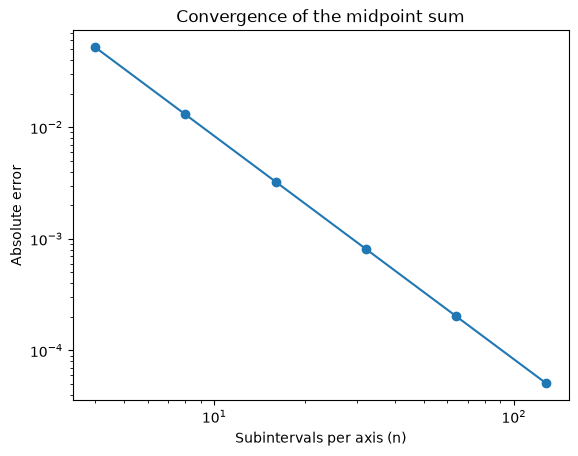

Error ratios when n doubles: [4. 4. 4. 4. 4.]


In [8]:
errors = np.abs(approxs - float(exact_value))

plt.loglog(ns, errors, "o-")
plt.xlabel("Subintervals per axis (n)")
plt.ylabel("Absolute error")
plt.title("Convergence of the midpoint sum")
plt.show()

print("Error ratios when n doubles:", errors[:-1] / errors[1:])

**Problem 6** Define the computational cost as the number of times we have to evaluate $f(x,y)$ to compute the Rienmann integration.  What happens to the computational cost if we double $n$?

An $n\times n$ grid uses $n^2$ evaluations of $f(x,y)$, one per midpoint. Doubling $n$ gives $(2n)^2=4n^2$ evaluations, so the cost quadruples.

# Monte Carlo Integration

Based on your answer to problem 6, you might start to get the idea that if we had a function with just a few more dimensions, 5-dimensional function $f(x_1,x_2,\dots x_5)$ for example, the cost of making a grid across the entire space adds up quickly!  Instead, we might try a technique that doesn't require creating a grid.  Here we will explore Monte Carlo integration.


## Calculating $\pi$

The other reason to try Monte Carlo integration is when the region you want to integrate over is difficult to handle with boxes.

Here we will use the region $R: x^2 + y^2 \le 1$ to compute $\pi$ based on the integral
$$
\iint_R 1 dA = \pi
$$
First, we will find the area of a unit circle inside a $2\times 2$ square box.  We will generate points at random inside the box, and count the number of points inside a circle of radius 1.  The area of the circle will calculated from
$$
\frac{\textrm{Area Circle}}{\textrm{Area Square}} = \frac{\textrm{Points inside Circle}}{\textrm{Total number of points}}
$$

**Problem 7:** Fill in the line of code below that estimates the value of $\pi$.

Estimated π = 3.1364
Error = 0.005192653589793039


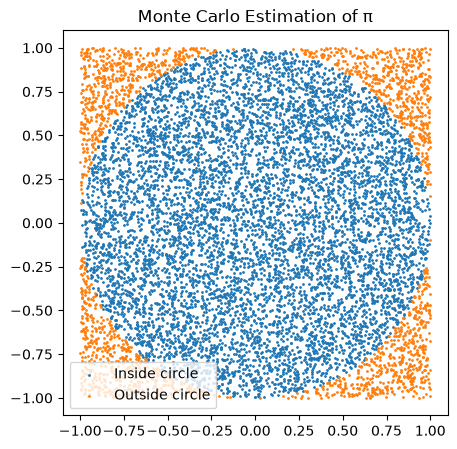

In [9]:
N = 10000  # number of random points
# generate points inside box with corners (-1,-1), (1,-1), (1,1), (-1,1)
rng = np.random.default_rng(7)
x, y = rng.uniform(-1, 1, size=(2, N))

inside = x**2 + y**2 <= 1
# The mean of the Boolean mask is the fraction inside the disk.
pi_estimate = 4 * inside.mean()

print(f"Estimated π = {pi_estimate}")
print(f"Error = {abs(np.pi - pi_estimate)}")

plt.figure(figsize=(5,5))
plt.scatter(x[inside], y[inside], s=1, label="Inside circle")
plt.scatter(x[~inside], y[~inside], s=1, label="Outside circle")
plt.legend()
plt.axis("square")
plt.title("Monte Carlo Estimation of π")
plt.show()

**Problem 8:** Perform a convergence study as a function of the number of points.  That is, determine the value of $\beta$ (to the nearest 1/2) such that
$$
\textrm{error} \propto \frac{1}{N^\beta}
$$
How does your value of $\beta$ compare to the value of $\alpha$ you found above for the grid method?

The root mean square error has slope near $-0.5$, giving $\beta=0.5$. Each sample contributes a zero or one to the fraction inside the disk, and the standard error of their average scales as $1/\sqrt{N}$. The grid result $\alpha=2$ uses $n$ subdivisions per axis. With $N=n^2$ total evaluations, the grid error in this example scales as $1/N$, while the Monte Carlo error scales as $1/\sqrt{N}$.

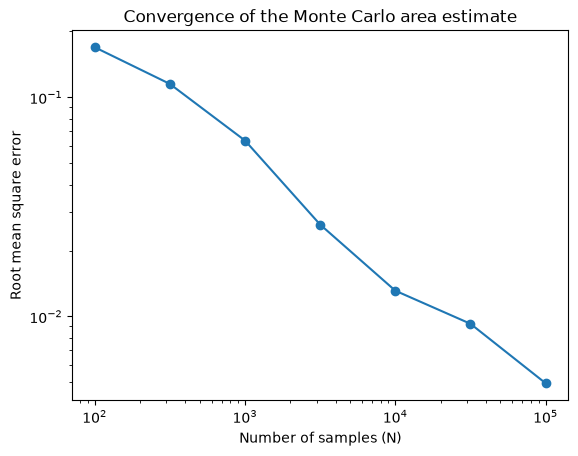

Log-log slope ≈ -0.53


In [10]:
rng = np.random.default_rng(235)
Ns = np.logspace(2, 5, 7, dtype=int)
errors = []

for N in Ns:
    estimates = np.empty(30)
    for trial in range(estimates.size):
        x, y = rng.uniform(-1, 1, size=(2, N))
        inside = x**2 + y**2 <= 1
        estimates[trial] = 4 * inside.mean()
    errors.append(np.sqrt(np.mean((estimates - np.pi)**2)))

plt.loglog(Ns, errors, "o-")
plt.xlabel("Number of samples (N)")
plt.ylabel("Root mean square error")
plt.title("Convergence of the Monte Carlo area estimate")
plt.show()

slope, _ = np.polyfit(np.log(Ns), np.log(errors), 1)
print(f"Log-log slope ≈ {slope:.2f}")

## Integration over the unit circle

Now we will use Monte Carlo integration to integrate a function over a region $R$.  The general idea is that the *average value* of a function is given by
$$
\bar{f} = \frac{\iint_R f(\vec x) dA}{area(R)}.
$$
We will compute $\bar{f}$ over points picked at random within the region the region $R$.

In particular, what if our function is a Gausian probability distribution between two correlated variables $x$ and $y$,
$$
f(x,y) = \frac{1}{2\pi\sqrt{(1-\rho^2)}}\exp\left[ \frac{-1}{2(1-\rho^2)}\left( x^2 + y^2 - 2\rho x y \right)\right]
$$
with $\rho\in[-1,1]$.  Take $\rho = 1/2$ in this section.  

**Problem 9:** Fill in the missing code to integrate $f(x,y)$ over the unit circle.  Use a large enough $N$ so that you are accurate to two decimal places.

The accepted points are uniform in the disk. Multiply their mean Gaussian density by the disk area $\pi$. With the seed below, the estimate is about $0.4246$, or $0.42$ to two decimal places.

In [11]:
def fxy(x, y):
    rho = 0.5
    q = 1 - rho**2
    exponent = -(x**2 + y**2 - 2*rho*x*y) / (2*q)
    return np.exp(exponent) / (2*np.pi*np.sqrt(q))

N = 1_000_000
rng = np.random.default_rng(9)
x, y = rng.uniform(-1, 1, size=(2, N))
inside = x**2 + y**2 <= 1

int_f = np.pi * fxy(x[inside], y[inside]).mean()
print(f"Estimated integral = {int_f:.6f}")

Estimated integral = 0.424598


## Integrate over the state of NC

Here is an even more complicated region, defined as a mask of a grayscale image.

Place the course file `NC_image.jpg` in the notebook's working directory, then rerun the image and integration cells.

In [12]:
from pathlib import Path
from PIL import Image

image_path = Path("NC_image.jpg")
mask = None

if image_path.is_file():
    with Image.open(image_path) as img:
        mask = np.array(img.convert("L")) > 128

    ny, nx = mask.shape
    rng = np.random.default_rng(25)
    col = rng.integers(0, nx, size=10_000)
    row = rng.integers(0, ny, size=10_000)
    inside = ~mask[row, col]

    plt.figure(figsize=(5, 5))
    plt.imshow(mask, extent=[0, nx, 0, ny], origin="upper", cmap="gray")
    x = col + 0.5
    y = ny - row - 0.5
    plt.scatter(x[inside], y[inside], s=1, label="Inside NC")
    plt.scatter(x[~inside], y[~inside], s=1, label="Outside NC")
    plt.legend()
    plt.title("Monte Carlo points in NC")
    plt.show()
else:
    print("Add the course image NC_image.jpg and rerun this cell.")

Add the course image NC_image.jpg and rerun this cell.


**Problem 10:** Fill in the code to integrate the Gaussian above over the state of NC.  I have recaled x and y for you to align better with the standard deviaion of the Gaussian.  Use enough points to get the answer to within 3 decimal places.

Each pixel has side length $2/n_x$ in the rescaled coordinates. The box has area $4n_y/n_x$. Average the Gaussian over all sampled pixels, assigning zero to samples outside NC, then multiply by the box area.

If the approximate 95% margin exceeds $0.0005$, quadruple $N$ and rerun the integration cell to roughly halve the margin. To check three-decimal rounding, round both ends of the reported interval and see whether they agree.

In [13]:
if mask is None:
    print("The NC integral needs the course image NC_image.jpg.")
else:
    N = 1_000_000
    rng = np.random.default_rng(10)
    ny, nx = mask.shape
    col = rng.integers(0, nx, size=N)
    row = rng.integers(0, ny, size=N)
    inside = ~mask[row, col]

    x = (col - nx/2) * (2/nx)
    y = (ny - row - ny/2) * (2/nx)

    box_area = 4 * ny / nx
    contributions = box_area * np.where(inside, fxy(x, y), 0.0)
    int_f_nc = contributions.mean()
    margin = 1.96 * contributions.std(ddof=1) / np.sqrt(N)

    print(f"Estimated integral = {int_f_nc:.6f}")
    print(f"Approximate 95% margin = {margin:.6f}")
    print(f"Approximate 95% interval = [{int_f_nc - margin:.6f}, "
          f"{int_f_nc + margin:.6f}]")

The NC integral needs the course image NC_image.jpg.
